In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal, chi2

In [8]:
rng = np.random.default_rng(42)

n_per_group = 30

A = rng.normal(loc=60, scale=8, size=n_per_group)
B = rng.normal(loc=65, scale=8, size=n_per_group)
C = rng.normal(loc=70, scale=8, size=n_per_group)

df = pd.DataFrame({
    "Method": ["A"] * n_per_group +
              ["B"] * n_per_group +
              ["C"] * n_per_group,
    "Score": np.concatenate([A, B, C])
})

df["Score"] = df["Score"].round(2)

df.head()

,Method,Score
0,A,62.44
1,A,51.68
2,A,66.00
3,A,67.52
4,A,44.39


In [9]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique groups:", df["Method"].nunique())
print(df["Method"].value_counts().sort_index())

print("\nUnique score values:", df["Score"].nunique())

Shape: (90, 2)

Data types:
Method        str
Score     float64
dtype: object

Missing values:
Method    0
Score     0
dtype: int64

Duplicate rows: 0

Unique groups: 3
Method
A    30
B    30
C    30
Name: count, dtype: int64

Unique score values: 89


In [10]:
assert df["Method"].notna().all()
assert df["Score"].notna().all()
assert df["Score"].map(np.isfinite).all()
assert set(df["Method"].unique()) == {"A", "B", "C"}
assert df.groupby("Method").size().eq(30).all()

print("Data validation passed.")

Data validation passed.


In [11]:
summary = df.groupby("Method")["Score"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

print(summary)

        count       mean  median       std    min    max
Method                                                  
A          30  60.134333  60.775  6.214152  44.39  69.78
B          30  65.910000  66.340  6.437823  53.34  82.13
C          30  69.186667  69.285  5.496400  56.54  76.86


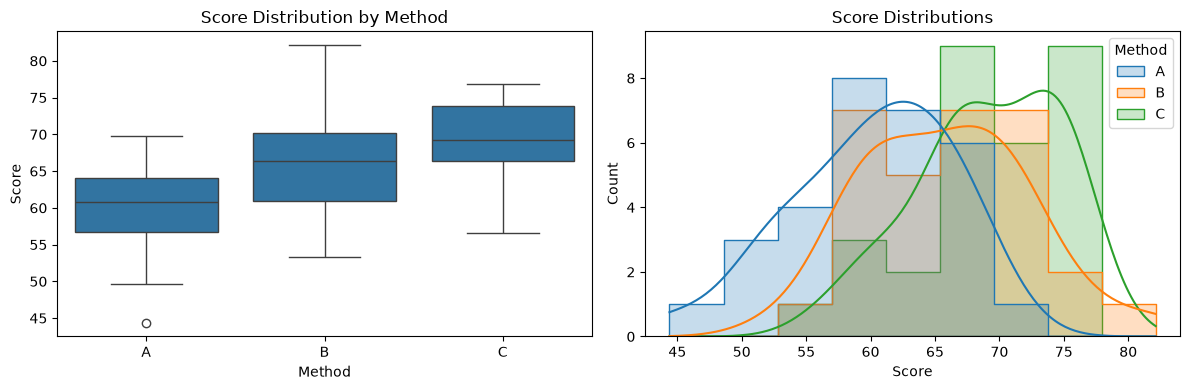

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Method", y="Score", ax=axes[0])
axes[0].set_title("Score Distribution by Method")

sns.histplot(
    data=df, x="Score", hue="Method",
    kde=True, element="step", ax=axes[1]
)
axes[1].set_title("Score Distributions")

plt.tight_layout()
plt.show()

In [13]:
alpha = 0.05

print("Significance level:", alpha)
print("Groups:", df["Method"].unique())
print("Total sample size:", len(df))

Significance level: 0.05
Groups: <StringArray>
['A', 'B', 'C']
Length: 3, dtype: str
Total sample size: 90


In [14]:
groups = [
    df.loc[df["Method"] == method, "Score"].to_numpy()
    for method in ["A", "B", "C"]
]

h_stat, p_value = kruskal(*groups)

k = len(groups)
df_dof = k - 1

critical_value = chi2.ppf(1 - alpha, df_dof)

print("H-statistic:", h_stat)
print("Degrees of freedom:", df_dof)
print("Critical value:", critical_value)
print("P-value:", p_value)

H-statistic: 24.925553159263753
Degrees of freedom: 2
Critical value: 5.991464547107979
P-value: 3.867986078092595e-06


In [15]:
if p_value < alpha:
    print("Reject H0")
    print("Evidence suggests at least one group distribution differs.")
else:
    print("Fail to reject H0")
    print("Insufficient evidence of a distributional difference.")

Reject H0
Evidence suggests at least one group distribution differs.


In [16]:
N = len(df)

epsilon_squared = (h_stat - k + 1) / (N - k)

print("Epsilon-squared:", epsilon_squared)

Epsilon-squared: 0.26351210527889374


In [18]:
import scikit_posthocs as sp

posthoc_results = sp.posthoc_dunn(
    df,
    val_col="Score",
    group_col="Method",
    p_adjust="holm"
)

posthoc_results

,A,B,C
A,1.000000,0.008440,0.000002
B,0.008440,1.000000,0.034638
C,0.000002,0.034638,1.000000
